In [33]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as matplotlib
sns.set()
import warnings
warnings.filterwarnings('ignore') 

In [34]:
iris=pd.read_csv("C:/Users/sweth/OneDrive/Pictures/Camera Roll/Iris.csv")
iris

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Unnamed: 6
0,1.0,5.1,3.5,1.4,0.2,Iris-setosa,NaN
1,2.0,4.9,3.0,1.4,0.2,Iris-setosa,NaN
2,3.0,4.7,3.2,1.3,0.2,Iris-setosa,NaN
3,4.0,4.6,3.1,1.5,0.2,Iris-setosa,NaN
4,5.0,5.0,3.6,1.4,0.2,Iris-setosa,NaN
...,...,...,...,...,...,...,...
146,147.0,6.3,2.5,5.0,1.9,Iris-virginica,NaN
147,148.0,6.5,3.0,5.2,2.0,Iris-virginica,NaN
148,149.0,6.2,3.4,5.4,2.3,Iris-virginica,NaN
149,150.0,5.9,3.0,5.1,1.8,Iris-virginica,NaN


In [35]:
iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 151 entries, 0 to 150
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    float64
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
 6   Unnamed: 6     0 non-null      float64
dtypes: float64(6), object(1)
memory usage: 8.4+ KB


In [36]:
iris.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Unnamed: 6
0,1.0,5.1,3.5,1.4,0.2,Iris-setosa,NaN
1,2.0,4.9,3.0,1.4,0.2,Iris-setosa,NaN
2,3.0,4.7,3.2,1.3,0.2,Iris-setosa,NaN
3,4.0,4.6,3.1,1.5,0.2,Iris-setosa,NaN
4,5.0,5.0,3.6,1.4,0.2,Iris-setosa,NaN


In [37]:
iris.tail()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Unnamed: 6
146,147.0,6.3,2.5,5.0,1.9,Iris-virginica,NaN
147,148.0,6.5,3.0,5.2,2.0,Iris-virginica,NaN
148,149.0,6.2,3.4,5.4,2.3,Iris-virginica,NaN
149,150.0,5.9,3.0,5.1,1.8,Iris-virginica,NaN
150,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [38]:
iris = iris.drop(columns=['Id','Unnamed: 6'])

In [39]:
iris.isnull().sum()

SepalLengthCm    1
SepalWidthCm     1
PetalLengthCm    1
PetalWidthCm     1
Species          1
dtype: int64

In [40]:
numerical_columns = [ 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']

for columns in numerical_columns:
    iris[columns] = iris[columns].fillna(iris[columns].median())

In [41]:
iris.isnull().sum()

SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          1
dtype: int64

In [42]:
categorical_columns = ['Species']

for columns in categorical_columns:
    iris[columns] = iris[columns].fillna(iris[columns].mode()[0])

In [43]:
print(iris.columns)

Index(['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')


In [44]:
print(iris.shape)

(151, 5)


In [45]:
iris.describe().T

,count,mean,std,min,25%,50%,75%,max
SepalLengthCm,151.0,5.843046,0.825309,4.3,5.1,5.80,6.4,7.9
SepalWidthCm,151.0,3.053642,0.432169,2.0,2.8,3.00,3.3,4.4
PetalLengthCm,151.0,3.762583,1.759187,1.0,1.6,4.35,5.1,6.9
PetalWidthCm,151.0,1.199338,0.760657,0.1,0.3,1.30,1.8,2.5


In [46]:
iris.dtypes

SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species           object
dtype: object

In [47]:
from sklearn.preprocessing import LabelEncoder

label_encoders = {}

cat_cols = ['Species']

for col in cat_cols:
    le = LabelEncoder()
    iris[col] = le.fit_transform(iris[col])
    label_encoders[col] = le

print("Encoding completed successfully!") 

Encoding completed successfully!


In [48]:
import joblib

joblib.dump(label_encoders, "label_encoders.pkl")

print("Label encoders saved successfully!")

Label encoders saved successfully!


In [49]:
loaded_encoders = joblib.load("label_encoders.pkl")

print(loaded_encoders.keys())

dict_keys(['Species'])


In [50]:
iris.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [51]:
iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 151 entries, 0 to 150
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  151 non-null    float64
 1   SepalWidthCm   151 non-null    float64
 2   PetalLengthCm  151 non-null    float64
 3   PetalWidthCm   151 non-null    float64
 4   Species        151 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [52]:
from sklearn.model_selection import train_test_split

# Features and Target
X = iris.drop("Species", axis=1)
y = iris["Species"]

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

print("Train Shape:", X_train.shape)
print("Test Shape :", X_test.shape)
print("Train Labels:", y_train.shape)
print("Test Labels :", y_test.shape)

Train Shape: (120, 4)
Test Shape : (31, 4)
Train Labels: (120,)
Test Labels : (31,)


In [53]:
#verify the class distribution
print("Training Set")
print(y_train.value_counts())

print("\nTesting Set")
print(y_test.value_counts())

Training Set
Species
2    41
0    40
1    39
Name: count, dtype: int64

Testing Set
Species
1    11
0    11
2     9
Name: count, dtype: int64


In [54]:
print("Before:", iris.shape)

iris= iris.drop_duplicates()

print("After:", iris.shape) 

Before: (151, 5)
After: (148, 5)


In [55]:
from sklearn.preprocessing import StandardScaler
import joblib

# Initialize scaler 
scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("Training Shape:", X_train_scaled.shape)
print("Testing Shape :", X_test_scaled.shape)

Feature scaling completed successfully!
Training Shape: (120, 4)
Testing Shape : (31, 4)


In [56]:
#Save and Verify Scaler

joblib.dump(scaler, "scaler.pkl")
print("Scaler saved successfully!")

loaded_scaler = joblib.load("scaler.pkl")
print(type(loaded_scaler)) 

Scaler saved successfully!
<class 'sklearn.preprocessing._data.StandardScaler'>


In [57]:
#SMOTE
from imblearn.over_sampling import SMOTE

# Initialize SMOTE
smote = SMOTE(random_state=42)

# Apply only on training data
X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_scaled,
    y_train
) 

print("SMOTE applied successfully!")

print("\nBefore SMOTE")
print(y_train.value_counts())

print("\nAfter SMOTE")
print(y_train_resampled.value_counts()) 

SMOTE applied successfully!

Before SMOTE
Species
2    41
0    40
1    39
Name: count, dtype: int64

After SMOTE
Species
0    41
2    41
1    41
Name: count, dtype: int64


In [67]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report,roc_auc_score)
# Train Model
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_resampled, y_train_resampled)

# Predictions
y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# Results
print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, average='weighted'))
print("Recall   :", recall_score(y_test, y_pred_lr, average='weighted'))
print("F1 Score :", f1_score(y_test, y_pred_lr, average='weighted'))
print("\nClassification Report")
print(classification_report(y_test, y_pred_lr))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_lr)) 


from sklearn.metrics import roc_auc_score

y_prob_lr = lr_model.predict_proba(X_test_scaled)

print("\nROC-AUC:",roc_auc_score(y_test,y_prob_lr,multi_class='ovr',average='weighted',labels=lr_model.classes_))

Accuracy : 0.967741935483871
Precision: 0.9704301075268816
Recall   : 0.967741935483871
F1 Score : 0.9674944311525451

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       0.92      1.00      0.96        11
           2       1.00      0.89      0.94         9

    accuracy                           0.97        31
   macro avg       0.97      0.96      0.97        31
weighted avg       0.97      0.97      0.97        31


Confusion Matrix
[[11  0  0]
 [ 0 11  0]
 [ 0  1  8]]

ROC-AUC: 1.0


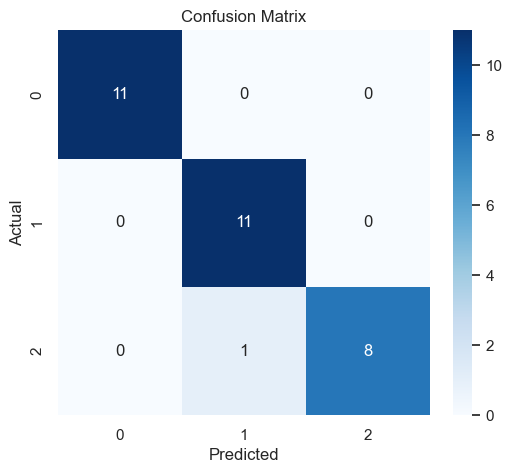

In [64]:
#CONFUSION MATRIX
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(6,5))

sns.heatmap(confusion_matrix(y_test,y_pred_lr),annot=True,fmt='d',cmap='Blues')

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [73]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_resampled, y_train_resampled)

y_pred_dt = dt_model.predict(X_test_scaled)
y_prob_dt = dt_model.predict_proba(X_test_scaled)

print("Accuracy:", accuracy_score(y_test,y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt, average='weighted'))
print("Recall   :", recall_score(y_test, y_pred_dt, average='weighted'))
print("F1 Score :", f1_score(y_test, y_pred_dt, average='weighted'))

print("\nClassification Report:")
print(classification_report(y_test,y_pred_dt))

print("Confusion Matrix:")
print(confusion_matrix(y_test,y_pred_dt))

print("\nROC-AUC:",roc_auc_score(y_test,y_prob_dt, multi_class='ovr',average='weighted', labels= dt_model.classes_))

Accuracy: 0.967741935483871
Precision: 0.9704301075268816
Recall   : 0.967741935483871
F1 Score : 0.9674944311525451

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       0.92      1.00      0.96        11
           2       1.00      0.89      0.94         9

    accuracy                           0.97        31
   macro avg       0.97      0.96      0.97        31
weighted avg       0.97      0.97      0.97        31

Confusion Matrix:
[[11  0  0]
 [ 0 11  0]
 [ 0  1  8]]

ROC-AUC: 0.9750000000000001


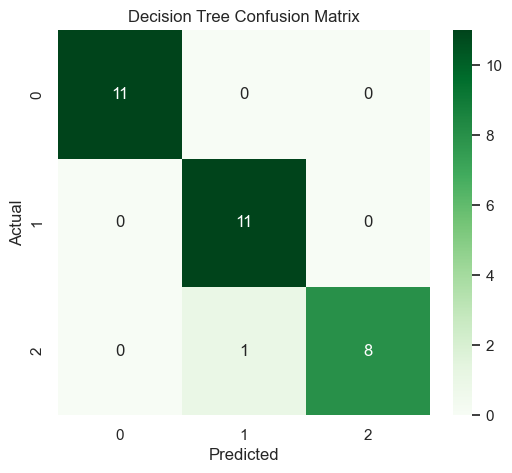

In [74]:
#confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Greens')

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [78]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=42,n_estimators=100)

rf_model.fit(X_train_resampled, y_train_resampled)

y_pred_rf = rf_model.predict(X_test_scaled)
y_prob_rf = rf_model.predict_proba(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, average='weighted'))
print("Recall   :", recall_score(y_test, y_pred_rf, average='weighted'))
print("F1 Score :", f1_score(y_test, y_pred_rf, average='weighted'))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nROC-AUC:",roc_auc_score(y_test,y_prob_rf, multi_class='ovr',average='weighted', labels= rf_model.classes_))

Accuracy: 0.967741935483871
Precision: 0.9704301075268816
Recall   : 0.967741935483871
F1 Score : 0.9674944311525451

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       0.92      1.00      0.96        11
           2       1.00      0.89      0.94         9

    accuracy                           0.97        31
   macro avg       0.97      0.96      0.97        31
weighted avg       0.97      0.97      0.97        31


Confusion Matrix:
[[11  0  0]
 [ 0 11  0]
 [ 0  1  8]]

ROC-AUC: 1.0


In [79]:
print("Training Accuracy:", rf_model.score(X_train, y_train))
print("Testing Accuracy :", rf_model.score(X_test, y_test))

Training Accuracy: 0.3416666666666667
Testing Accuracy : 0.2903225806451613


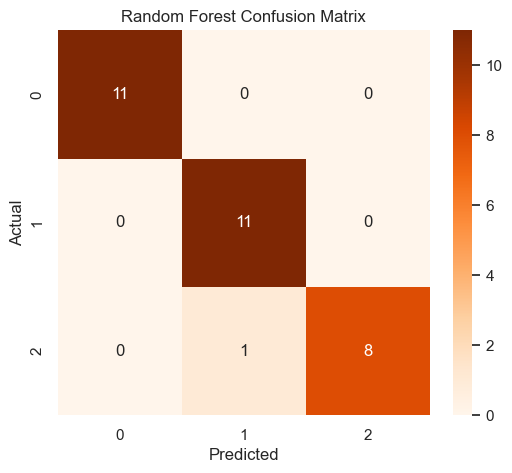

In [80]:
#confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Oranges')

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [83]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(random_state=42,eval_metric="logloss")

xgb_model.fit(X_train_resampled, y_train_resampled)

y_pred_xgb = xgb_model.predict(X_test_scaled)
y_prob_xgb = xgb_model.predict_proba(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb, average='weighted'))
print("Recall   :", recall_score(y_test, y_pred_xgb, average='weighted'))
print("F1 Score :", f1_score(y_test, y_pred_xgb, average='weighted'))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print("\nROC-AUC:",roc_auc_score(y_test,y_prob_xgb, multi_class='ovr',average='weighted', labels= xgb_model.classes_))

Accuracy: 0.9354838709677419
Precision: 0.9381720430107526
Recall   : 0.9354838709677419
F1 Score : 0.9352363666364161

Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96        11
           1       0.91      0.91      0.91        11
           2       1.00      0.89      0.94         9

    accuracy                           0.94        31
   macro avg       0.94      0.93      0.94        31
weighted avg       0.94      0.94      0.94        31


Confusion Matrix:
[[11  0  0]
 [ 1 10  0]
 [ 0  1  8]]

ROC-AUC: 0.9983870967741937


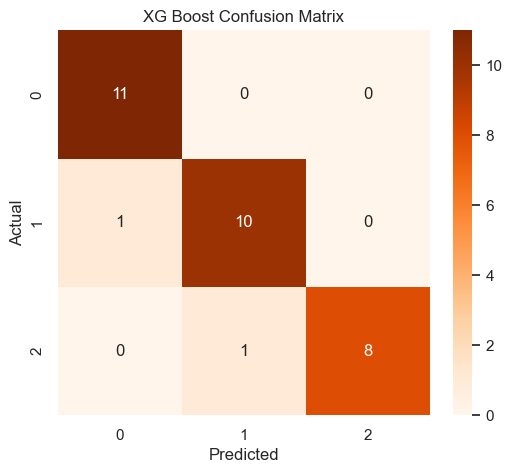

In [84]:
#confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Oranges')

plt.title("XG Boost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [88]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_resampled, y_train_resampled)

y_pred_knn = knn_model.predict(X_test_scaled) 
y_prob_knn = knn_model.predict_proba(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn, average='weighted'))
print("Recall   :", recall_score(y_test, y_pred_knn, average='weighted'))
print("F1 Score :", f1_score(y_test, y_pred_knn, average='weighted'))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nROC-AUC:",roc_auc_score(y_test,y_prob_knn, multi_class='ovr',average='weighted', labels= knn_model.classes_))


Accuracy: 0.967741935483871
Precision: 0.9704301075268816
Recall   : 0.967741935483871
F1 Score : 0.9674944311525451

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       0.92      1.00      0.96        11
           2       1.00      0.89      0.94         9

    accuracy                           0.97        31
   macro avg       0.97      0.96      0.97        31
weighted avg       0.97      0.97      0.97        31


Confusion Matrix:
[[11  0  0]
 [ 0 11  0]
 [ 0  1  8]]

ROC-AUC: 1.0


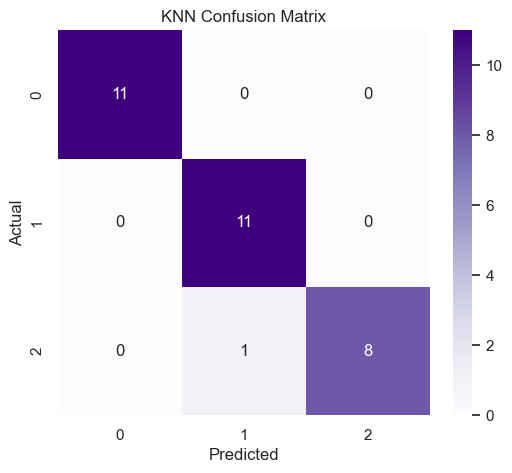

In [86]:
#confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Purples')

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [90]:
from sklearn.svm import SVC

svm_model = SVC(kernel="rbf",probability=True,random_state=42)

svm_model.fit(X_train_resampled, y_train_resampled)

y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm, average='weighted'))
print("Recall   :", recall_score(y_test, y_pred_svm, average='weighted'))
print("F1 Score :", f1_score(y_test, y_pred_svm, average='weighted'))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

print("\nROC-AUC:",roc_auc_score(y_test,y_prob_svm, multi_class='ovr',average='weighted', labels= svm_model.classes_))

Accuracy: 0.967741935483871
Precision: 0.9704301075268816
Recall   : 0.967741935483871
F1 Score : 0.9674944311525451

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       0.92      1.00      0.96        11
           2       1.00      0.89      0.94         9

    accuracy                           0.97        31
   macro avg       0.97      0.96      0.97        31
weighted avg       0.97      0.97      0.97        31


Confusion Matrix:
[[11  0  0]
 [ 0 11  0]
 [ 0  1  8]]

ROC-AUC: 1.0


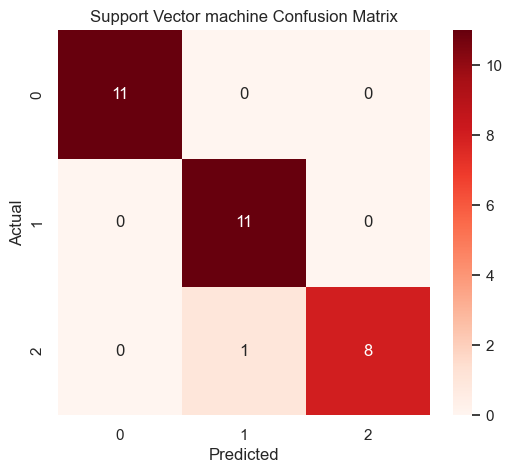

In [91]:
#confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Reds')

plt.title("Support Vector machine Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual") 
plt.show() 

In [96]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Store model names and trained models
models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "KNN": knn_model,
    "SVM": svm_model
}

results = []

for name, model in models.items():

    # Predictions
    y_pred = model.predict(X_test_scaled)

    # Probabilities for ROC-AUC
    y_prob = model.predict_proba(X_test_scaled)
    

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average='weighted'),
        "Recall": recall_score(y_test, y_pred, average='weighted'),
        "F1 Score": f1_score(y_test, y_pred, average='weighted'),
        "ROC-AUC":roc_auc_score(y_test,y_prob, multi_class='ovr',average='weighted', labels= model.classes_)
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.967742,0.970430,0.967742,0.967494,1.000000
1,Decision Tree,0.967742,0.970430,0.967742,0.967494,0.975000
2,Random Forest,0.967742,0.970430,0.967742,0.967494,1.000000
3,KNN,0.967742,0.970430,0.967742,0.967494,1.000000
4,SVM,0.967742,0.970430,0.967742,0.967494,1.000000
5,XGBoost,0.935484,0.938172,0.935484,0.935236,0.998387


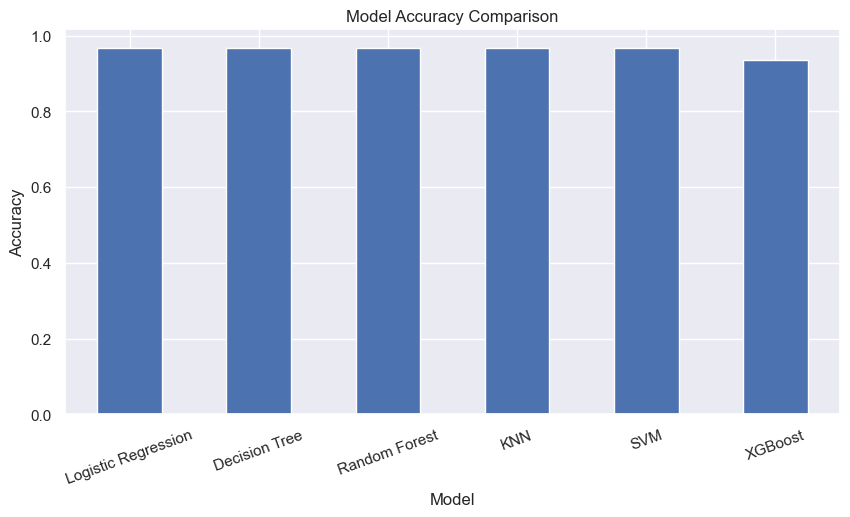

In [97]:
#Visual Comparision 
import matplotlib.pyplot as plt

comparison_df.plot(
    x="Model",
    y="Accuracy", 
    kind="bar",
    figsize=(10,5),
    legend=False
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.show()

In [98]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Parameter Grid 
dt_params = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
} 

dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt_params, 
    cv=5,
    scoring="accuracy", 
    n_jobs=-1
) 

dt_grid.fit(X_train_resampled, y_train_resampled)

best_dt = dt_grid.best_estimator_

print("Best Parameters:", dt_grid.best_params_) 

Best Parameters: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 2}


In [102]:
#Evaluate Tuned Decision Tree
y_pred_dt = best_dt.predict(X_test_scaled)
y_prob_dt = best_dt.predict_proba(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt, average='weighted'))
print("Recall:", recall_score(y_test, y_pred_dt, average='weighted'))
print("F1 Score:", f1_score(y_test, y_pred_dt, average='weighted'))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

print("\nConfusion Matrix:") 
print(confusion_matrix(y_test, y_pred_dt)) 

print("\nROC-AUC:",roc_auc_score(y_test,y_prob_dt, multi_class='ovr',average='weighted', labels= dt_model.classes_))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       1.00      1.00      1.00        11
           2       1.00      1.00      1.00         9

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31


Confusion Matrix:
[[11  0  0]
 [ 0 11  0]
 [ 0  0  9]]

ROC-AUC: 1.0


In [103]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Parameter Grid
rf_params = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=rf_params,
    n_iter=20,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train_resampled, y_train_resampled)

best_rf = rf_search.best_estimator_

print("Best Parameters:", rf_search.best_params_)

Best Parameters: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': None}


In [105]:
#Evaluate Tuned Random Forest
y_pred_rf = best_rf.predict(X_test_scaled)
y_prob_rf = best_rf.predict_proba(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, average='weighted'))
print("Recall:", recall_score(y_test, y_pred_rf, average='weighted'))
print("F1 Score:", f1_score(y_test, y_pred_rf, average='weighted'))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:") 
print(confusion_matrix(y_test, y_pred_rf)) 

print("\nROC-AUC:",roc_auc_score(y_test,y_prob_rf, multi_class='ovr',average='weighted', labels= rf_model.classes_))

Accuracy: 0.967741935483871
Precision: 0.9704301075268816
Recall: 0.967741935483871
F1 Score: 0.9674944311525451

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       0.92      1.00      0.96        11
           2       1.00      0.89      0.94         9

    accuracy                           0.97        31
   macro avg       0.97      0.96      0.97        31
weighted avg       0.97      0.97      0.97        31


Confusion Matrix:
[[11  0  0]
 [ 0 11  0]
 [ 0  1  8]]

ROC-AUC: 1.0


In [106]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Parameter Grid
xgb_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, 9],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

xgb_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    ),
    param_distributions=xgb_params,
    n_iter=20,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

xgb_search.fit(X_train_resampled, y_train_resampled)

best_xgb = xgb_search.best_estimator_

print("Best Parameters:", xgb_search.best_params_)

Best Parameters: {'subsample': 1.0, 'n_estimators': 300, 'max_depth': 9, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


In [107]:
#Evaluate Tuned XG Boost 
y_pred_xgb = best_xgb.predict(X_test_scaled)
y_prob_xgb = best_xgb.predict_proba(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb, average='weighted'))
print("Recall:", recall_score(y_test, y_pred_xgb, average='weighted'))
print("F1 Score:", f1_score(y_test, y_pred_xgb, average='weighted'))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

print("\nConfusion Matrix:") 
print(confusion_matrix(y_test, y_pred_xgb)) 

print("\nROC-AUC:",roc_auc_score(y_test,y_prob_xgb, multi_class='ovr',average='weighted', labels= xgb_model.classes_))

Accuracy: 0.9354838709677419
Precision: 0.9381720430107526
Recall: 0.9354838709677419
F1 Score: 0.9352363666364161

Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96        11
           1       0.91      0.91      0.91        11
           2       1.00      0.89      0.94         9

    accuracy                           0.94        31
   macro avg       0.94      0.93      0.94        31
weighted avg       0.94      0.94      0.94        31


Confusion Matrix:
[[11  0  0]
 [ 1 10  0]
 [ 0  1  8]]

ROC-AUC: 0.9983870967741937


In [108]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Parameter Grid
lr_params = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs'],
    'max_iter': [500, 1000, 2000]
}

lr_search = RandomizedSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_distributions=lr_params,
    n_iter=20,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

lr_search.fit(X_train_resampled, y_train_resampled)

best_lr = lr_search.best_estimator_

print("Best Parameters:", lr_search.best_params_)

Best Parameters: {'solver': 'lbfgs', 'max_iter': 2000, 'C': 10}


In [109]:
#Evaluate tuned logistic regression
y_pred_lr = best_lr.predict(X_test_scaled)
y_prob_lr = best_lr.predict_proba(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, average='weighted'))
print("Recall   :", recall_score(y_test, y_pred_lr, average='weighted'))
print("F1 Score :", f1_score(y_test, y_pred_lr, average='weighted'))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nROC-AUC:",roc_auc_score(y_test,y_prob_lr, multi_class='ovr',average='weighted', labels= lr_model.classes_))

Accuracy: 0.967741935483871
Precision: 0.9704301075268816
Recall   : 0.967741935483871
F1 Score : 0.9674944311525451

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       0.92      1.00      0.96        11
           2       1.00      0.89      0.94         9

    accuracy                           0.97        31
   macro avg       0.97      0.96      0.97        31
weighted avg       0.97      0.97      0.97        31


Confusion Matrix:
[[11  0  0]
 [ 0 11  0]
 [ 0  1  8]]

ROC-AUC: 1.0


In [110]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Parameter Grid
knn_params = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski'],
    'p': [1, 2]
}

knn_search = RandomizedSearchCV(
    estimator=KNeighborsClassifier(),
    param_distributions=knn_params,
    n_iter=20,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

knn_search.fit(X_train_resampled, y_train_resampled)

best_knn = knn_search.best_estimator_

print("Best Parameters:", knn_search.best_params_)

Best Parameters: {'weights': 'uniform', 'p': 1, 'n_neighbors': 9, 'metric': 'euclidean'}


In [113]:
#Evaluate tuned KNN
y_pred_knn = best_knn.predict(X_test_scaled)
y_prob_knn = best_knn.predict_proba(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn, average='weighted'))
print("Recall   :", recall_score(y_test, y_pred_knn, average='weighted'))
print("F1 Score :", f1_score(y_test, y_pred_knn, average='weighted'))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nROC-AUC:",roc_auc_score(y_test,y_prob_knn, multi_class='ovr',average='weighted', labels= knn_model.classes_))

Accuracy: 0.967741935483871
Precision: 0.9704301075268816
Recall   : 0.967741935483871
F1 Score : 0.9674944311525451

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       0.92      1.00      0.96        11
           2       1.00      0.89      0.94         9

    accuracy                           0.97        31
   macro avg       0.97      0.96      0.97        31
weighted avg       0.97      0.97      0.97        31


Confusion Matrix:
[[11  0  0]
 [ 0 11  0]
 [ 0  1  8]]

ROC-AUC: 0.9953812316715543


In [114]:
from sklearn.model_selection import cross_val_score


In [116]:
from sklearn.model_selection import cross_val_score
import pandas as pd

models = { 
    "Decision Tree": best_dt,
    "Random Forest": best_rf,
    "XGBoost": best_xgb
}

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train_scaled,
        y_train,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Cross Validation Accuracy": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

cv_df = cv_df.sort_values(
    by="Cross Validation Accuracy",
    ascending=False
).reset_index(drop=True)
 
cv_df

,Model,Cross Validation Accuracy,Standard Deviation
0,Random Forest,0.941667,0.042492
1,XGBoost,0.941667,0.042492
2,Decision Tree,0.933333,0.050000


In [117]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=42)

scores_dt = cross_val_score(best_dt,X,y,cv=5,scoring='accuracy')

print("Decision Tree Cross Validation Scores:",scores_dt)
print("Average Accuracy:", scores_dt.mean())
print("Standard Deviation:", scores_dt.std())

Decision Tree Cross Validation Scores: [0.96774194 0.96666667 0.93333333 0.93333333 0.96666667]
Average Accuracy: 0.9535483870967744
Standard Deviation: 0.016510191585091816


In [119]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state=42)

scores_rf = cross_val_score(best_rf,X,y,cv=5,scoring='accuracy')

print("Random Forest Cross Validation Scores:",scores_rf)
print("Average Accuracy:", scores_rf.mean())
print("Standard Deviation:", scores_rf.std()) 


Random Forest Cross Validation Scores: [0.96774194 0.96666667 0.93333333 0.96666667 0.96666667]
Average Accuracy: 0.960215053763441
Standard Deviation: 0.013447310280312671


In [124]:
scores_xgb = cross_val_score(best_xgb,X,y,cv=5,scoring='accuracy')

print("XGBOOST Cross Validation Scores:",scores_xgb) 
print("Average Accuracy:", scores_xgb.mean())
print("Standard Deviation:", scores_xgb.std())

XGBOOST Cross Validation Scores: [0.96774194 0.96666667 0.93333333 0.93333333 0.93333333]
Average Accuracy: 0.9468817204301077
Standard Deviation: 0.01659680118845139


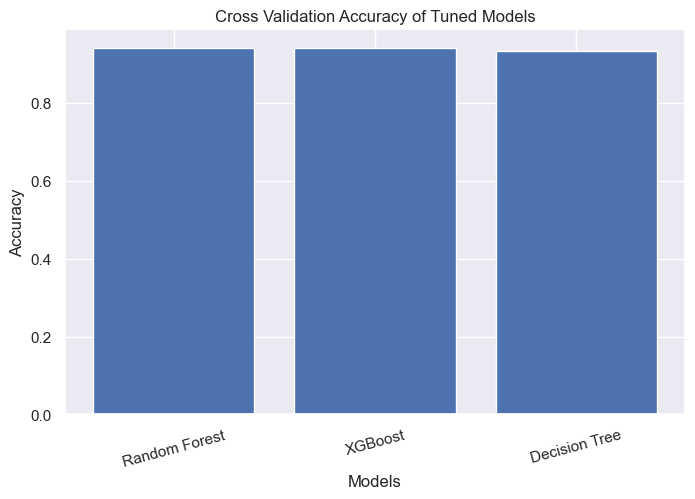

In [125]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(
    cv_df["Model"],
    cv_df["Cross Validation Accuracy"]
)

plt.title("Cross Validation Accuracy of Tuned Models")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=15)

plt.show()

In [126]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance
importance = best_rf.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
2,PetalLengthCm,0.452572
3,PetalWidthCm,0.419139
0,SepalLengthCm,0.108498
1,SepalWidthCm,0.019791


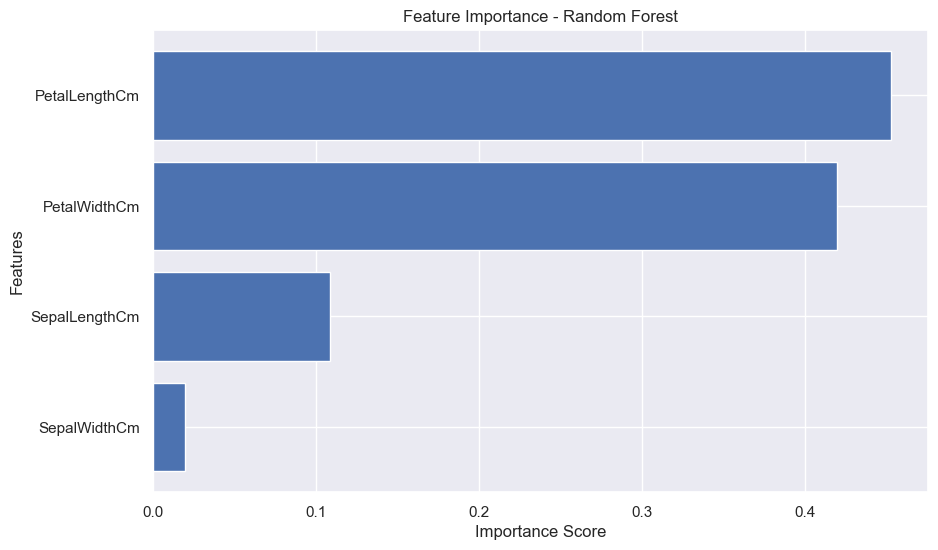

In [127]:
#Visualise
plt.figure(figsize=(10,6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"] 
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.gca().invert_yaxis()

plt.show()

In [128]:
import joblib  

joblib.dump(best_dt, "Decision_Tree_model.pkl") 

print("Decision Tree model saved successfully.")  

Decision Tree model saved successfully.


In [129]:
#Verify the model  
loaded_model = joblib.load("Decision_Tree_model.pkl") 
         
print(type(loaded_model))   

<class 'sklearn.tree._classes.DecisionTreeClassifier'>
